In [6]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))
# Now import Model from freeflux

import numpy as np

import seaborn as sns
import analysis.io_func as io_func
import analysis.an_func as an_func
import matplotlib.pyplot as plt
from analysis import config_13c as config


In [7]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [11]:
condition = cond = 'WT'

In [ ]:
model=config.model
net_flux_df=config.net_flux_df(condition)
obj_vals=config.obj_vals(condition)


## technical plots are 
- C) same plot : hist of residuals from u,1 and u+1 
- D) 3 suplobts : scatters of 1 vs u , u+1 vs 1 , u+1 vs u 


### plot C  : distribution of residuals from u,1 and u+1

<Axes: xlabel='Residual'>

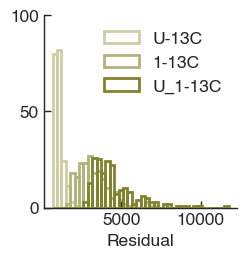

In [ ]:
## with same bar width

fig, ax = plt.subplots(1, 1, figsize=(2.5, 2.5))
io_func.scale_rcparams(fig)
                       

bins = 40  # Number of bins
all_data = np.concatenate([obj_tm6_1, obj_tm6_u, obj_tm6_comb])  # Combine all datasets
bin_edges = np.histogram_bin_edges(all_data, bins=bins)  # Compute common bin edges
sns.histplot(obj_tm6_u, ax=ax, label='U-13C', facecolor='none', bins=bin_edges,edgecolor=palette[3],linewidth=2)#,element='step')
sns.histplot(obj_tm6_1, ax=ax, label='1-13C', facecolor='none', bins=bin_edges,edgecolor=palette[5],linewidth=2)#,element='step'

obj_tm6_comb_samesize = np.random.choice(obj_tm6_comb, len(obj_tm6_1), replace=False)
sns.histplot(obj_tm6_comb_samesize, ax=ax, label='U_1-13C', facecolor='none', bins=bin_edges,zorder=5,edgecolor=palette[2],linewidth=2)#,element='step')

ax.legend(edgecolor='none', loc='best')
ax.set_xlabel('Residual')
ax.set_ylabel('')
io_func.rescale_axlim(ax,how='y',nbins=3)

# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/fig5b_residualshist_alllabels_tm6_noface.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/fig5b_residualshist_alllabels_tm6_noface.svg',dpi=300,bbox_inches='tight')




### plot D scatter of residuals, 2 by 2

In [ ]:
cfg['settings_scatterplots']['edgecolor']='none'

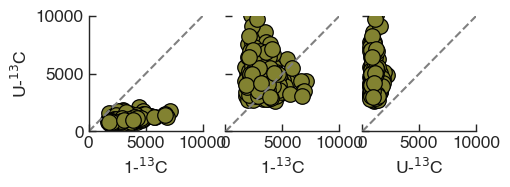

In [ ]:
## 
fig,axes=plt.subplots(1,3,figsize=(5,1.5),sharey=True)
io_func.scale_rcparams(fig,scalingf=0.5)
## scatter plot of obj u vs obj 1
sns.scatterplot(x=obj_tm6_1,y=obj_tm6_u,ax=axes[0],**cfg['settings_scatterplots'],color=palette[2])
axes[0].set_xlabel('1-$^{13}$C')
axes[0].set_ylabel('U-$^{13}$C')

## scatter plot of obj comb vs obj 1
sns.scatterplot(x=obj_tm6_1,y=obj_tm6_comb,ax=axes[1],**cfg['settings_scatterplots'],color=palette[2])
axes[1].set_xlabel('1-$^{13}$C')
axes[1].set_ylabel('U+1-$^{13}$C')
# axes[1].set_xlim(0,1e4)

## scatter plot of obj comb vs obj u
sns.scatterplot(x=obj_tm6_u,y=obj_tm6_comb,ax=axes[2],**cfg['settings_scatterplots'],color=palette[2])
axes[2].set_xlabel('U-$^{13}$C')
axes[2].set_ylabel('U+1-$^{13}$C')


#conf plots
for i,ax in enumerate(axes):
    ax.locator_params(axis='both', nbins=2)
    ax.plot([0,1],[0,1],transform=ax.transAxes,**cfg['settings_diagonal'])
    ax.set_xlim(0,1e4)
    ax.set_ylim(0,1e4)

axes[1].spines['left'].set_visible(False)
axes[2].spines['left'].set_visible(False)


# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/fig5a_3subs_residualsscatters.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{OUTPUT_FOLDER_PLOTS}/fig5a_3subs_residualsscatters.svg',dpi=300,bbox_inches='tight')

